<a href="https://colab.research.google.com/github/VictoriaHThompson/streaming-churn-modulo4/blob/master/Modulo2_aulas12e13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mount Google Drive and Load Excel Data

First, we need to authorize Google Colab to access your Google Drive files. Then, we will use `pandas` to load the dataset.

In [ ]:
import os
import pandas as pd

# Direct target file
target_file = "dados_modelo_antigo.xlsx"
search_start_dir = "/content/drive/MyDrive/C O U R S E S"
found_paths = []

# Search strictly in the C O U R S E S directory to avoid long walk times
if os.path.exists(search_start_dir):
    for root, dirs, files in os.walk(search_start_dir):
        if target_file in files:
            found_paths.append(os.path.join(root, target_file))

if found_paths:
    exact_path = found_paths[0]
    print(f"Found the file at: {exact_path}")
    df = pd.read_excel(exact_path)
    print("File successfully loaded!")
    display(df.head())
else:
    print(f"Could not locate {target_file} inside {search_start_dir}.")

Found the file at: /content/drive/MyDrive/C O U R S E S/Pós-Graduação em Data Science + IA da UNIPDS/1 - Dados, IA e Negócio/Slides/2-business_analytics/exercicio_pyhon_business_analytics/dados_modelo_antigo.xlsx
File successfully loaded!


,valor_compra,score_fraude_modelo,fraude
0,5.64,66,0
1,124.71,72,0
2,339.32,95,0
3,3.54,2,0
4,3.53,76,0


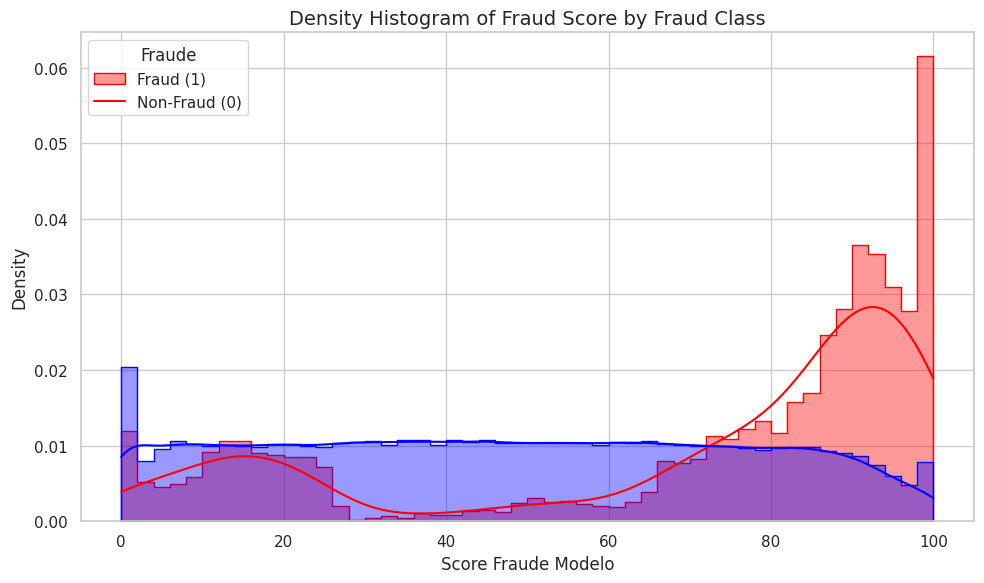

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")

# Create the density histogram with specific color palette mapping
# fraude = 0 -> blue, fraude = 1 -> red
custom_colors = {0: "blue", 1: "red"}

plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="score_fraude_modelo",
    hue="fraude",
    kde=True,
    stat="density",
    common_norm=False,
    bins=50,
    palette=custom_colors,
    alpha=0.4,       # Set transparency to clearly see the overlap
    element="step"   # "step" helps visualize overlapping distributions clearly
)

plt.title("Density Histogram of Fraud Score by Fraud Class", fontsize=14)
plt.xlabel("Score Fraude Modelo", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(title="Fraude", labels=["Fraud (1)", "Non-Fraud (0)"])

plt.tight_layout()
plt.show()

In [ ]:
# Show basic structure, columns, types, and non-null counts
print("=== DataFrame Info ===")
df.info()

# Provide descriptive statistical summary for numeric columns
print("\n=== Descriptive Statistics ===")
display(df.describe())

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 3 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   valor_compra         150000 non-null  float64
 1   score_fraude_modelo  150000 non-null  int64  
 2   fraude               150000 non-null  int64  
dtypes: float64(1), int64(2)
memory usage: 3.4 MB

=== Descriptive Statistics ===


,valor_compra,score_fraude_modelo,fraude
count,150000.000000,150000.000000,150000.000000
mean,43.523134,48.066240,0.050000
std,91.557888,28.995122,0.217946
min,0.020000,0.000000,0.000000
25%,9.380000,23.000000,0.000000
50%,20.610000,48.000000,0.000000
75%,40.692500,73.000000,0.000000
max,3696.350000,100.000000,1.000000
